# Full Fine-Tuning: Training-Label Noise Experiments

**MIA5150 — Full BERT fine-tuning**  
**Team:** Callum Anderson and Zaynab Othman Taha

All BERT parameters and the classification head will be trained.

## Imports


In [ ]:
import hashlib
import json
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, set_seed

from IPython.display import display


# 1. Verify GPU, as it will be needed for this experiment

In [ ]:
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Load the prepared data and set the experiment conditions

The conditions are **0%, 10%, 20%, and 40% added training-label noise**, with
**seeds 42, 43, and 44**. 

In [ ]:
LABEL_COLUMN = "label (target)"
NUMBER_OF_CLASSES = 11
CLASS_IDS = np.arange(NUMBER_OF_CLASSES)
NOISE_PERCENTAGES = (0, 10, 20, 40)
RANDOM_SEEDS = (42, 43, 44)
SPLIT_NAMES = ("train", "validation", "test")

DATA_DIRECTORY = Path("/content")
source_paths = {split: DATA_DIRECTORY / f"{split}_merged.csv" for split in SPLIT_NAMES}
missing_files = [path.name for path in source_paths.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Missing files in /content: {', '.join(missing_files)}. "
        "Upload the three cleaned CSVs directly to the Colab Files panel."
    )

source_hashes = {
    split: hashlib.sha256(path.read_bytes()).hexdigest()
    for split, path in source_paths.items()
}
data_splits = {
    split: pd.read_csv(path, dtype={"paper_id": "string"})
    for split, path in source_paths.items()
}
for split, frame in data_splits.items():
    assert frame["paper_id"].notna().all() and frame["paper_id"].is_unique, split
    assert pd.api.types.is_integer_dtype(frame[LABEL_COLUMN]), split
    assert set(frame[LABEL_COLUMN]) == set(CLASS_IDS), split
    for text_column in ("title", "abstract"):
        assert frame[text_column].fillna("").str.strip().ne("").all(), split

for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
    assert set(data_splits[left]["paper_id"]).isdisjoint(data_splits[right]["paper_id"])

training_data = data_splits["train"]
validation_data = data_splits["validation"]
test_data = data_splits["test"]
original_training_labels = training_data[LABEL_COLUMN].to_numpy(dtype=np.int64, copy=True)
original_training_labels.setflags(write=False)
original_split_labels = {split: frame[LABEL_COLUMN].copy(deep=True) for split, frame in data_splits.items()}
class_names = training_data.groupby(LABEL_COLUMN)["classname"].first().reindex(CLASS_IDS)
for frame in data_splits.values():
    assert frame["classname"].eq(frame[LABEL_COLUMN].map(class_names)).all()

split_totals = pd.DataFrame({
    "Split": SPLIT_NAMES,
    "Records": [len(data_splits[split]) for split in SPLIT_NAMES],
    "Classes": [data_splits[split][LABEL_COLUMN].nunique() for split in SPLIT_NAMES],
})
print(f"Loaded {split_totals['Records'].sum():,} unique papers from {DATA_DIRECTORY}.")
display(split_totals)

print("\nThree example training records (original labels):")
training_examples = training_data[["paper_id", "title", "abstract", "classname", LABEL_COLUMN]].head(3)
display(training_examples)


Loaded 23,335 unique papers from /content.


,Split,Records,Classes
0,train,16334,11
1,validation,3499,11
2,test,3502,11



Three example training records (original labels):


,paper_id,title,abstract,classname,label (target)
0,dda7899c46b7764ed16ab3092f4f9476a9cecedf,Sampling of the anterior apical region results...,OBJECTIVE\nTo evaluate whether biopsy cores ta...,Neoplasms (cancer),9
1,16d289c10d9834d6fcb2870ba0d6cb5fd839e9a3,Telephone-administered cognitive behavioral th...,OBJECTIVE\nMultiple trials have found telephon...,Mental disorders,7
2,a1337bbf7cff59dcd9d63600ac80eb90f191a26e,Efficacy and safety of the seven-day buprenorp...,CONTEXT\nThis article presents the results of ...,Musculoskeletal disorders,8


# 3. Add symmetric training-label noise

For each condition, select records **proportionally from each original training class**
and replace each selected label uniformly with **one of the other ten classes**.
Every selected label therefore changes. Validation and test labels stay unchanged.


In [ ]:
def add_symmetric_label_noise(original_labels, noise_percent, seed):
    """Return independent noisy labels and a mask of changed records."""
    labels = np.asarray(original_labels)
    if labels.ndim != 1 or labels.size == 0 or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("Labels must be a nonempty one-dimensional integer array.")
    if not np.isin(labels, CLASS_IDS).all():
        raise ValueError("Labels must be integers from 0 to 10.")
    if not isinstance(noise_percent, (int, np.integer)) or not 0 <= noise_percent <= 100:
        raise ValueError("noise_percent must be an integer between 0 and 100.")
    if not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError("seed must be a nonnegative integer.")

    noisy_labels = labels.copy()
    changed_mask = np.zeros(len(labels), dtype=bool)
    original_class_counts = np.bincount(labels, minlength=NUMBER_OF_CLASSES)
    quota_numerators = original_class_counts * noise_percent
    flips_per_class = quota_numerators // 100
    target_flips = (len(labels) * noise_percent + 50) // 100
    remaining = int(target_flips - flips_per_class.sum())
    remainder_order = np.argsort(-(quota_numerators % 100), kind="stable")
    flips_per_class[remainder_order[:remaining]] += 1

    rng = np.random.default_rng(np.random.SeedSequence([int(seed), int(noise_percent)]))
    for class_id, number_to_flip in enumerate(flips_per_class):
        if number_to_flip == 0:
            continue
        eligible_positions = np.flatnonzero(labels == class_id)
        chosen_positions = rng.choice(eligible_positions, size=int(number_to_flip), replace=False)
        alternative_labels = CLASS_IDS[CLASS_IDS != class_id]
        noisy_labels[chosen_positions] = rng.choice(alternative_labels, size=int(number_to_flip))
        changed_mask[chosen_positions] = True

    assert changed_mask.sum() == target_flips
    assert np.array_equal(changed_mask, noisy_labels != labels)
    return noisy_labels, changed_mask


## 3.1 Generate the reusable label variants

`training_label_variants[(seed, noise_percent)]` holds the labels aligned with
`training_data`. That same entry is used for frozen BERT, LoRA, and full fine-tuning.



In [ ]:
training_label_variants = {}
noise_audits = {}
summary_rows = []

for seed in RANDOM_SEEDS:
    for noise_percent in NOISE_PERCENTAGES:
        noisy_labels, changed_mask = add_symmetric_label_noise(
            original_training_labels, noise_percent, seed
        )
        noisy_labels.setflags(write=False)
        key = (seed, noise_percent)
        training_label_variants[key] = noisy_labels
        noise_audits[key] = pd.DataFrame({
            "paper_id": training_data["paper_id"].to_numpy(copy=True),
            "original_label": original_training_labels.copy(),
            "noisy_label": noisy_labels.copy(),
            "label_changed": changed_mask.copy(),
        })
        summary_rows.append({
            "Seed": seed,
            "Requested noise (%)": noise_percent,
            "Training records": len(noisy_labels),
            "Changed labels": int(changed_mask.sum()),
            "Unchanged labels": int((~changed_mask).sum()),
            "Actual noise (%)": 100 * changed_mask.mean(),
        })

noise_summary = pd.DataFrame(summary_rows)
display(noise_summary.round({"Actual noise (%)": 4}))


,Seed,Requested noise (%),Training records,Changed labels,Unchanged labels,Actual noise (%)
0,42,0,16334,0,16334,0.0000
1,42,10,16334,1633,14701,9.9976
2,42,20,16334,3267,13067,20.0012
3,42,40,16334,6534,9800,40.0024
4,43,0,16334,0,16334,0.0000
5,43,10,16334,1633,14701,9.9976
6,43,20,16334,3267,13067,20.0012
7,43,40,16334,6534,9800,40.0024
8,44,0,16334,0,16334,0.0000
9,44,10,16334,1633,14701,9.9976


## 3.2 Verify the scheme

Check exact flip totals, proportional allocation, valid replacement labels,
reproducibility, and alignment to paper IDs. Also confirm the original labels and
all three source files are unchanged. These checks do not establish that the
original disease labels are semantically correct.

In [ ]:
original_class_counts = np.bincount(original_training_labels, minlength=NUMBER_OF_CLASSES)
for (seed, noise_percent), noisy_labels in training_label_variants.items():
    audit = noise_audits[(seed, noise_percent)]
    changed = noisy_labels != original_training_labels
    expected_flips = (len(training_data) * noise_percent + 50) // 100
    assert int(changed.sum()) == expected_flips
    assert np.isin(noisy_labels, CLASS_IDS).all()
    assert not np.shares_memory(noisy_labels, original_training_labels)
    assert np.array_equal(audit["paper_id"], training_data["paper_id"])
    assert np.array_equal(audit["original_label"], original_training_labels)
    assert np.array_equal(audit["noisy_label"], noisy_labels)
    assert np.array_equal(audit["label_changed"], changed)

    actual_per_class = np.bincount(original_training_labels[changed], minlength=NUMBER_OF_CLASSES)
    lower_quota = original_class_counts * noise_percent // 100
    upper_quota = (original_class_counts * noise_percent + 99) // 100
    assert ((actual_per_class >= lower_quota) & (actual_per_class <= upper_quota)).all()
    repeated_labels, repeated_mask = add_symmetric_label_noise(
        original_training_labels, noise_percent, seed
    )
    assert np.array_equal(noisy_labels, repeated_labels)
    assert np.array_equal(changed, repeated_mask)

for split, frame in data_splits.items():
    pd.testing.assert_series_equal(frame[LABEL_COLUMN], original_split_labels[split])
    assert hashlib.sha256(source_paths[split].read_bytes()).hexdigest() == source_hashes[split]
assert np.array_equal(training_data[LABEL_COLUMN], original_training_labels)
print("Passed: all 12 variants are reproducible, correctly allocated, and aligned.")
print("Original training, validation, test labels and CSV files remain unchanged.")


Passed: all 12 variants are reproducible, correctly allocated, and aligned.
Original training, validation, test labels and CSV files remain unchanged.


# 4. Exploratory data analysis

These charts describe the prepared dataset and injected label changes. Original labels may contain natural errors, so “unchanged” does not
mean “correct.” 

## 4.1 Split totals and changed training labels

Flip totals are the same for all three seeds; the selected papers and replacement
labels vary. The second panel therefore shows one bar per noise level.

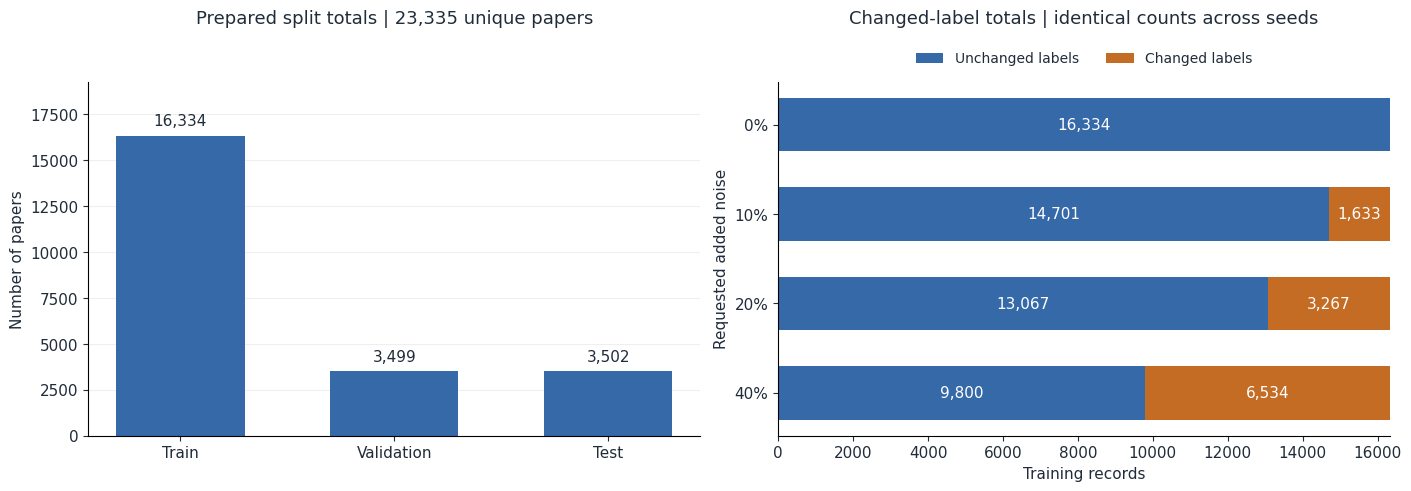

In [ ]:
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "#202C3A", "axes.labelcolor": "#202C3A",
    "xtick.color": "#202C3A", "ytick.color": "#202C3A",
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREY = "#3569A8", "#C46B24", "#667788"
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout="constrained")

bars = axes[0].bar(split_totals["Split"].str.title(), split_totals["Records"], color=BLUE, width=0.6)
axes[0].bar_label(bars, labels=[f"{n:,}" for n in split_totals["Records"]], padding=5)
axes[0].set_ylim(0, split_totals["Records"].max() * 1.18)
axes[0].set_ylabel("Number of papers")
axes[0].set_title(f"Prepared split totals | {split_totals['Records'].sum():,} unique papers", pad=42)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)

counts_by_level = noise_summary[noise_summary["Seed"] == RANDOM_SEEDS[0]]
y = np.arange(len(counts_by_level))
unchanged = counts_by_level["Unchanged labels"].to_numpy()
changed = counts_by_level["Changed labels"].to_numpy()
axes[1].barh(y, unchanged, color=BLUE, label="Unchanged labels", height=0.6)
axes[1].barh(y, changed, left=unchanged, color=ORANGE, label="Changed labels", height=0.6)
for position, n_unchanged, n_changed in zip(y, unchanged, changed):
    axes[1].text(n_unchanged / 2, position, f"{n_unchanged:,}", ha="center", va="center", color="white")
    if n_changed:
        axes[1].text(n_unchanged + n_changed / 2, position, f"{n_changed:,}", ha="center", va="center", color="white")
axes[1].set_yticks(y, [f"{p}%" for p in counts_by_level["Requested noise (%)"]])
axes[1].invert_yaxis()
axes[1].set_xlim(0, len(training_data))
axes[1].set_xlabel("Training records")
axes[1].set_ylabel("Requested added noise")
axes[1].set_title("Changed-label totals | identical counts across seeds", pad=42)
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False, fontsize=10)
plt.show()


## 4.2 Inspect a noisy training condition

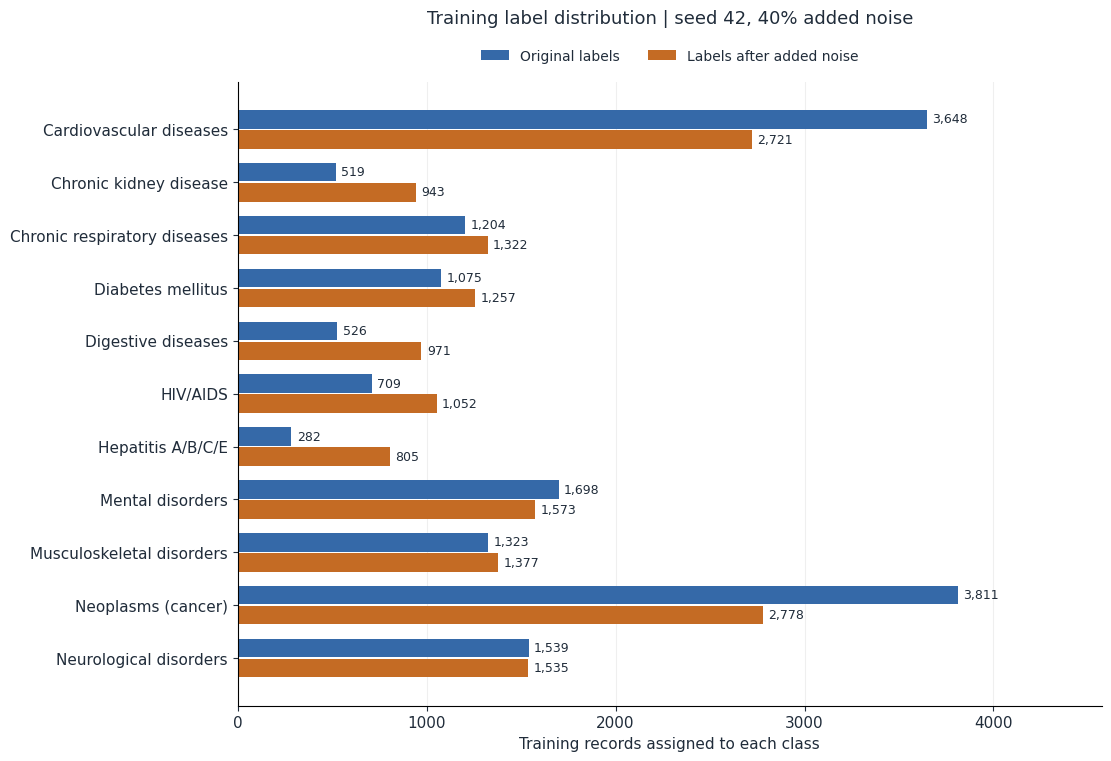

Changed labels: 6,534 / 16,334.


,paper_id,Original class,Assigned class after noise
0,dda7899c46b7764ed16ab3092f4f9476a9cecedf,Neoplasms (cancer),HIV/AIDS
1,16d289c10d9834d6fcb2870ba0d6cb5fd839e9a3,Mental disorders,HIV/AIDS
6,3719ee40c3e1ce8c4c32c608c727150ab2d406dd,HIV/AIDS,Musculoskeletal disorders
8,9b4afe90d27a131874294966d4eba4791f1819e1,Musculoskeletal disorders,HIV/AIDS
10,c7aedf53cecc37b35e35b4c725b5fd9d1a9b5779,Mental disorders,Hepatitis A/B/C/E


In [ ]:
EDA_SEED = 42
EDA_NOISE_PERCENT = 40
selected_key = (EDA_SEED, EDA_NOISE_PERCENT)
selected_audit = noise_audits[selected_key]
selected_labels = training_label_variants[selected_key]
original_counts = np.bincount(original_training_labels, minlength=NUMBER_OF_CLASSES)
noisy_counts = np.bincount(selected_labels, minlength=NUMBER_OF_CLASSES)

fig, ax = plt.subplots(figsize=(11, 7.5), layout="constrained")
y = np.arange(NUMBER_OF_CLASSES)
original_bars = ax.barh(y - 0.19, original_counts, height=0.35, color=BLUE, label="Original labels")
noisy_bars = ax.barh(y + 0.19, noisy_counts, height=0.35, color=ORANGE, label="Labels after added noise")
for bars, values in ((original_bars, original_counts), (noisy_bars, noisy_counts)):
    ax.bar_label(bars, labels=[f"{n:,}" for n in values], padding=4, fontsize=9)
ax.set_yticks(y, class_names.tolist())
ax.invert_yaxis()
ax.set_xlim(0, max(original_counts.max(), noisy_counts.max()) * 1.2)
ax.set_xlabel("Training records assigned to each class")
ax.set_title(f"Training label distribution | seed {EDA_SEED}, {EDA_NOISE_PERCENT}% added noise", pad=42)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False, fontsize=10)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

changed_examples = selected_audit.loc[selected_audit["label_changed"]].head(5).copy()
changed_examples["Original class"] = changed_examples["original_label"].map(class_names)
changed_examples["Assigned class after noise"] = changed_examples["noisy_label"].map(class_names)
print(f"Changed labels: {selected_audit['label_changed'].sum():,} / {len(training_data):,}.")
display(changed_examples[["paper_id", "Original class", "Assigned class after noise"]])


# 5. Tokenize titles and abstracts

BERT-base-uncased tokenizer and 256-token limit.


In [ ]:
BERT_CHECKPOINT_NAME = "google-bert/bert-base-uncased"
MAXIMUM_TOKEN_LENGTH = 256

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_CHECKPOINT_NAME, use_fast=True)


def tokenize_papers(paper_data):
    return bert_tokenizer(
        text=paper_data["title"].tolist(),
        text_pair=paper_data["abstract"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAXIMUM_TOKEN_LENGTH,
        return_tensors="pt",
    )


tokenized_splits = {
    split: tokenize_papers(data_splits[split])
    for split in SPLIT_NAMES
}
training_tokenized_inputs = tokenized_splits["train"]
validation_tokenized_inputs = tokenized_splits["validation"]
test_tokenized_inputs = tokenized_splits["test"]

print("Tokenizer:", BERT_CHECKPOINT_NAME)
print("Maximum sequence length:", MAXIMUM_TOKEN_LENGTH)
for split, encoded_inputs in tokenized_splits.items():
    expected_shape = (len(data_splits[split]), MAXIMUM_TOKEN_LENGTH)
    for input_name in ("input_ids", "attention_mask", "token_type_ids"):
        assert tuple(encoded_inputs[input_name].shape) == expected_shape, (split, input_name)
    print(f"{split}: {expected_shape[0]:,} records × {expected_shape[1]} tokens")


Tokenizer: google-bert/bert-base-uncased
Maximum sequence length: 256
train: 16,334 records × 256 tokens
validation: 3,499 records × 256 tokens
test: 3,502 records × 256 tokens
